# Predicting Mouse Choice from Neural Activity

## Question

Can neural activity be used to predict whether the animal makes a left or right choice?

In this notebook, we use trial-level neural activity from the IBL Brain-Wide Map dataset and train a logistic regression classifier to predict the animal's choice.

The true choices stored in the trials data are used to evaluate the prediction accuracy.

## 1. Install Required Packages

We first install the IBL packages required to access and work with the Brain-Wide Map dataset.

`ONE-api` provides access to IBL datasets, while `ibllib` contains utilities used for working with IBL data.

In [1]:
%pip install ONE-api --quiet
%pip install ibllib --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## 2. Set Up the IBL Data Interface

The IBL data are accessed through the ONE (Open Neurophysiology Environment) interface.

Here, we configure ONE to connect to the public IBL OpenAlyx server. This interface will also provide the local cache directory where the downloaded Neuromatch dataset is stored.

In [2]:
import os

# When running in Jupyter set number of threads to 1
os.environ.setdefault('ONE_HTTP_DL_THREADS', '1')

from one.api import ONE

ONE.setup(base_url='https://openalyx.internationalbrainlab.org',silent=True)

one = ONE(password='international')

Connected to https://openalyx.internationalbrainlab.org as user "intbrainlab"


## 3. Import Libraries

We import the libraries needed for data loading, manipulation, and classification.

The analysis mainly uses NumPy and pandas for data processing, SciPy for loading sparse neural activity matrices, and scikit-learn for training and evaluating the logistic regression classifier.

In [3]:
import numpy as np
import pandas as pd

from scipy import sparse
from iblutil.util import Bunch

from one.remote.aws import s3_download_file

import zipfile

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt

## 4. Define a Function to Download the Preprocessed Data

The Neuromatch tutorial provides preprocessed neural activity aligned to several behavioral events.

The function below downloads the requested dataset from the IBL storage and extracts it into the local ONE cache directory.

For this analysis, we will later use neural activity aligned to the animal's first movement (`firstMove`).

In [4]:
def download_data(event):
    assert event in ['firstMove', 'stimOn', 'feedback'], \
        'event must be one of "firstMove", "stimOn" or "feedback"'

    # Dataset name
    fname = f'data_{event}.zip'

    # Remote location of data
    s3_data_path = f'sample_data/Neuromatch/{fname}'

    # Local location
    save_path = one.cache_dir.joinpath('Neuromatch', fname)
    save_path.parent.mkdir(exist_ok=True, parents=True)

    # Download
    file = s3_download_file(s3_data_path, save_path)

    # Unzip
    with zipfile.ZipFile(file, 'r') as zip_ref:
        zip_ref.extractall(save_path.parent)

## 5. Locate the Downloaded Dataset

After downloading the data, we need a consistent way to locate the corresponding folder in the ONE cache.

This helper function returns the local path for a dataset aligned to a specified behavioral event.

In [5]:
def get_data_path(event):
    return one.cache_dir.joinpath('Neuromatch',f'data_{event}')

## 6. Load Dataset Metadata

The dataset contains several metadata tables describing the recorded neurons, trials, and recording sessions.

We also load the time vector associated with the neural activity. These timestamps specify the neural activity bins relative to the alignment event.

The resulting metadata object contains:

- cluster information,
- trial information,
- session information,
- time bins,
- sampling interval,
- and the local data path.

In [6]:
def load_metadata(event):

    metadata = Bunch()

    data_path = get_data_path(event)

    metadata['clusters'] = pd.read_parquet(data_path.joinpath('clusters.pqt'))

    metadata['trials'] = pd.read_parquet(data_path.joinpath('trials.pqt'))

    metadata['sessions'] = pd.read_parquet(data_path.joinpath('sessions.pqt'))

    metadata['times'] = np.load(data_path.joinpath('t.npy'))

    metadata['nbins'] = metadata['times'].size

    metadata['dt'] = np.round(np.median(np.diff(metadata['times'])),2)

    metadata['data_path'] = data_path

    return metadata

## 7. Load Trial-Level Neural Activity

For each probe insertion, neural activity is stored as a sparse PSTH matrix.

The following function loads this matrix, converts it to a dense array, and reshapes it into:

**trials × neurons × time bins**

This representation allows us to examine the activity of every recorded neuron on every behavioral trial.

In [7]:
def load_psth(data_path, pid, nbins=150):

    psth = sparse.load_npz(data_path.joinpath(f'{pid}.npz')).toarray()

    psth = psth.reshape(psth.shape[0],-1,nbins)

    return psth

## 8. Load Neural and Behavioral Data for One Probe Insertion

For the decoding analysis, neural activity and behavioral choices must correspond to the same recording session.

This helper function loads the PSTH for one probe insertion and matches it with:

- the recorded cluster information,
- the corresponding session,
- and the trial-level behavioral data.

The function returns three objects:

`psth` — trial-level neural activity  
`clust_df` — information about the recorded neurons  
`trials_df` — behavioral information for each trial

In [8]:
def get_psth_for_insertion(pid, meta, reg=None, uuids=None):

    df = meta.clusters[meta.clusters['pid'] == pid]

    df = df[['acronym', 'pid', 'uuids', 'cluster_id', 'psth_index']]

    sp = load_psth(meta.data_path,pid,nbins=meta.nbins)

    if reg is not None:
        in_reg = df['acronym'] == reg
        sp = sp[:, in_reg.values, :]
        df = df[in_reg].reset_index(drop=True)

    if uuids is not None:
        in_uuid = df['uuids'].isin(uuids)
        sp = sp[:, in_uuid.values, :]
        df = df[in_uuid].reset_index(drop=True)

    eid = meta.sessions[meta.sessions['pid'] == pid].iloc[0]['eid']

    trials = meta.trials[meta.trials['eid'] == eid].reset_index(drop=True)

    psth = sp / meta['dt']

    return psth, df, trials

## 9. Download Neural Activity Aligned to First Movement

Our goal is to predict the animal's choice from neural activity immediately before the choice-related movement occurs.

Therefore, we use the dataset aligned to `firstMove`, where time zero corresponds to the animal's first detected movement on each trial.

In [9]:
download_data('firstMove')

(S3) C:\Users\user\Downloads\ONE\openalyx.internationalbrainlab.org\Neuromatch\data_firstMove.zip: 100%|██████████| 823M/823M [01:40<00:00, 8.16MB/s] 


## 10. Load the First-Movement Metadata

We now load the metadata associated with the `firstMove` dataset.

We also inspect the time vector and bin size to understand the temporal range of neural activity available around the movement event.

In [10]:
meta = load_metadata('firstMove')
print(meta.times.shape)
print(meta.times[0], meta.times[-1])
print(meta.dt)

(150,)
-0.495 0.995
0.01


## 11. Select a Probe Insertion

To build a simple baseline decoder, we begin with a single probe insertion.

We use the same example probe insertion used in the reference tutorial and load both its neural activity and the corresponding behavioral trials.

In [11]:
pid = '8ca1a850-26ef-42be-8b28-c2e2d12f06d6'
psth, clust_df, trials_df = get_psth_for_insertion(pid,meta)

## 12. Inspect the Loaded Data

Before constructing the classifier, we inspect the dimensions of the neural and behavioral data.

The number of trials in the PSTH should correspond to the number of rows in the trial table, while the second PSTH dimension represents the recorded neural clusters.

In [12]:
print("PSTH shape:", psth.shape)
print("Number of clusters:", len(clust_df))
print("Number of trials:", len(trials_df))





PSTH shape: (569, 172, 150)
Number of clusters: 172
Number of trials: 569


In [13]:
trials_df.head()

,eid,probabilityLeft,feedbackType,contrastLeft,contrastRight,choice,psth_index,block,block_trial_number
0,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,NaN,1.0,-1.0,0,0,0
1,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,0.125,NaN,1.0,1,0,1
2,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,1.000,NaN,1.0,2,0,2
3,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,0.125,NaN,1.0,3,0,3
4,15763234-d21e-491f-a01b-1238eb96d389,0.5,1.0,NaN,1.0,-1.0,4,0,7


In [14]:
clust_df.head()

,acronym,pid,uuids,cluster_id,psth_index
73620,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,94a99b56-a69e-4b82-871e-1a869521a57a,0,0
73621,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,0a54cfe9-d78b-4447-adef-ae0352fbdc03,18,1
73622,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,7af4a528-42d0-45cd-a26a-5efa8871b56c,25,2
73623,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,96fa5343-d325-46e8-a572-32c053f05ee2,26,3
73624,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,6185cfae-98dd-4eb0-81d5-11b5ccca5e22,27,4


## 13. Inspect the Choice Labels

The target variable for our classifier is the animal's choice on each trial.

The `choice` column in the trials table contains the behavioral choice labels. We inspect their distribution before training the classifier.

In [15]:
trials_df['choice'].value_counts()

choice
 1.0    388
-1.0    181
Name: count, dtype: int64

## 14. Select Neural Activity Before Movement

To predict the animal's upcoming choice, we focus on neural activity occurring before the movement itself.

Following the reference tutorial, we select the 100 ms period immediately preceding the first movement:

**-100 ms to 0 ms relative to first movement**

This prevents the model from using neural activity occurring after movement onset.

In [16]:
time_mask = np.bitwise_and(meta.times < 0,meta.times > -0.1)

print(meta.times[time_mask])

[-0.095 -0.085 -0.075 -0.065 -0.055 -0.045 -0.035 -0.025 -0.015 -0.005]


## 15. Construct the Neural Feature Matrix

The PSTH initially has three dimensions:

**trials × neurons × time**

Logistic regression requires a two-dimensional feature matrix:

**samples × features**

We therefore average the neural activity across the selected 100 ms time window.

After averaging, each trial is represented by one feature value per recorded neuron. Thus, every row of `X` represents one trial and every column represents one neuron.

In [17]:
X = psth[:, :, time_mask].mean(axis=2)

print("Original PSTH:", psth.shape)
print("Model input X:", X.shape)

Original PSTH: (569, 172, 150)
Model input X: (569, 172)


In [18]:
y = trials_df.choice.values

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", np.unique(y))
assert X.shape[0] == y.shape[0]

X shape: (569, 172)
y shape: (569,)
Classes: [-1.  1.]


## 16.1. Check for Missing Values

Before splitting the data into training and test sets, we check whether the neural feature matrix (`X`) or the choice labels (`y`) contain missing values.

Some columns in the trial metadata, such as `contrastLeft` and `contrastRight`, contain NaN values. However, these NaNs are part of the task structure and these variables are not used as inputs to the current classifier.

The current model only uses:

- `X`: neural activity features
- `y`: the animal's left/right choice

Therefore, we only need to verify that these two variables do not contain missing values.

In [19]:
print("NaNs in neural features (X):", np.isnan(X).sum())
print("NaNs in choice labels (y):", np.isnan(y).sum())

assert not np.isnan(X).any(), "X contains NaN values"
assert not np.isnan(y).any(), "y contains NaN values"

nan_counts = trials_df.isna().sum()

print("Columns containing NaN values:")
print(nan_counts[nan_counts > 0])

NaNs in neural features (X): 0
NaNs in choice labels (y): 0
Columns containing NaN values:
contrastLeft     217
contrastRight    352
dtype: int64


### 16.2. Choice Modulation Index

Before training the decoder, we first ask whether individual neurons show different activity depending on the animal's upcoming choice.

For each neuron, we compare its mean activity during the 100 ms period before movement for left-choice and right-choice trials.

Following the modulation-index idea used in the reference tutorial, we define the choice modulation index as:

$$
\mathrm{Choice\ MI}
=
\frac{
\left| FR_{\mathrm{right}} - FR_{\mathrm{left}} \right|
}{
\left| FR_{\mathrm{right}} + FR_{\mathrm{left}} \right|
}
$$

where:

- $FR_{\mathrm{right}}$ is the mean pre-movement activity for right-choice trials.
- $FR_{\mathrm{left}}$ is the mean pre-movement activity for left-choice trials.

A value close to zero indicates similar activity for the two choices, whereas a larger value indicates stronger choice-related modulation.

This analysis is descriptive and is separate from the logistic-regression decoding analysis below.

In [20]:
# Mean activity for each neuron on left- and right-choice trials
left_mean = X[y == -1].mean(axis=0)
right_mean = X[y == 1].mean(axis=0)

# Choice modulation index
denominator = np.abs(left_mean + right_mean)

choice_mi = np.divide(
    np.abs(right_mean - left_mean),
    denominator,
    out=np.zeros_like(denominator, dtype=float),
    where=denominator > 0
)

# Store results alongside cluster metadata
choice_df = clust_df.copy()

choice_df['left_mean'] = left_mean
choice_df['right_mean'] = right_mean
choice_df['choice_mi'] = choice_mi

choice_df.sort_values(
    'choice_mi',
    ascending=False
).head(10)

,acronym,pid,uuids,cluster_id,psth_index,left_mean,right_mean,choice_mi
73765,SSp-tr,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,4fcdc326-92b6-4c93-bc57-3af3c8d698be,725,145,0.000000,0.128866,1.000000
73761,CA1,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,5fc661ae-4d87-4058-a238-04c32f396331,684,141,0.000000,0.798969,1.000000
73778,SSp-tr,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,dbd0c485-8045-4049-b0da-05fc6898f0c7,779,158,3.425414,0.695876,0.662302
73680,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,8b120c40-8f55-48c6-a064-d925a553afee,285,60,35.248619,9.948454,0.559774
73631,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,44b8541b-0959-497c-a2e2-1653d4b40580,48,11,0.441989,0.154639,0.481623
73747,CA3,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,fd8bdfa0-e065-4e17-a925-99ddd1954830,518,127,0.441989,0.154639,0.481623
73763,CA1,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,b9b7db43-d9d4-428f-99a9-25e150ec5d08,692,143,0.055249,0.154639,0.473541
73726,LD,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,980427b8-00e4-42ea-ab44-a51189c7446f,444,106,0.220994,0.567010,0.439104
73677,PO,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,99904206-9ba7-4554-ae6e-cbe97d88c4e3,275,57,0.607735,1.520619,0.428916
73776,SSp-tr,8ca1a850-26ef-42be-8b28-c2e2d12f06d6,12330fd2-603b-4a52-a8d0-ef48c9e2e6a0,773,156,0.607735,0.257732,0.404409


### 16.3. Test Choice Modulation Against a Shuffled Null Distribution

A high modulation index alone does not prove that the neuron is genuinely related to choice.

To estimate how much modulation could occur by chance, we repeatedly shuffle the left/right choice labels while keeping the neural activity unchanged.

For each neuron, the observed choice MI is compared with a null distribution obtained from shuffled choice labels.

We then calculate an empirical permutation p-value and apply a false-discovery-rate (FDR) correction across neurons.

In [21]:
rng = np.random.default_rng(0)

n_permutations = 1000
n_neurons = X.shape[1]

null_mi = np.zeros(
    (n_permutations, n_neurons)
)

for i in range(n_permutations):

    # Shuffle choice labels
    y_shuffled = rng.permutation(y)

    left_shuffled = X[y_shuffled == -1].mean(axis=0)
    right_shuffled = X[y_shuffled == 1].mean(axis=0)

    denominator = np.abs(
        left_shuffled + right_shuffled
    )

    null_mi[i] = np.divide(
        np.abs(right_shuffled - left_shuffled),
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator > 0
    )

In [22]:
# Empirical permutation p-values
observed_mi = choice_df['choice_mi'].values

p_values = (
    1 +
    (null_mi >= observed_mi).sum(axis=0)
) / (n_permutations + 1)


# Benjamini-Hochberg FDR correction
def fdr_bh(p_values):

    p_values = np.asarray(p_values)

    order = np.argsort(p_values)
    ranked_p = p_values[order]

    m = len(p_values)

    q_ranked = (
        ranked_p * m /
        np.arange(1, m + 1)
    )

    q_ranked = np.minimum.accumulate(
        q_ranked[::-1]
    )[::-1]

    q_values = np.empty(m)

    q_values[order] = np.clip(
        q_ranked,
        0,
        1
    )

    return q_values


q_values = fdr_bh(p_values)

choice_df['p_perm'] = p_values
choice_df['q_fdr'] = q_values

choice_df['significant_choice_modulation'] = (
    choice_df['q_fdr'] < 0.05
)

print(
    "Significantly choice-modulated neurons:",
    choice_df['significant_choice_modulation'].sum(),
    "/",
    len(choice_df)
)

Significantly choice-modulated neurons: 57 / 172


In [23]:
choice_df[
    [
        'acronym',
        'cluster_id',
        'choice_mi',
        'p_perm',
        'q_fdr',
        'significant_choice_modulation'
    ]
].sort_values(
    'choice_mi',
    ascending=False
).head(15)

,acronym,cluster_id,choice_mi,p_perm,q_fdr,significant_choice_modulation
73765,SSp-tr,725,1.000000,0.142857,0.245714,False
73761,CA1,684,1.000000,0.000999,0.005925,True
73778,SSp-tr,779,0.662302,0.000999,0.005925,True
73680,PO,285,0.559774,0.000999,0.005925,True
73631,PO,48,0.481623,0.069930,0.156207,False
73747,CA3,518,0.481623,0.316683,0.442842,False
73763,CA1,692,0.473541,0.556444,0.678782,False
73726,LD,444,0.439104,0.166833,0.274925,False
73677,PO,275,0.428916,0.034965,0.089761,False
73776,SSp-tr,773,0.404409,0.128871,0.235807,False


### 16.4. Summarize Choice Modulation by Brain Region

Each recorded neuron is associated with a brain-region acronym.

We therefore group the neurons from the current probe insertion by brain region and summarize:

- the number of recorded neurons,
- the median choice modulation index,
- and the proportion of neurons that remain significant after FDR correction.

Because a single probe insertion may contain only a small number of neurons from some regions, these results should be treated as exploratory. A brain-wide analysis across many insertions will be performed later.

In [24]:
insertion_region_summary = (
    choice_df
    .groupby('acronym')
    .agg(
        n_clusters=('choice_mi', 'size'),
        median_choice_mi=('choice_mi', 'median'),
        mean_choice_mi=('choice_mi', 'mean'),
        significant_fraction=(
            'significant_choice_modulation',
            'mean'
        )
    )
    .sort_values(
        'median_choice_mi',
        ascending=False
    )
)

insertion_region_summary

,n_clusters,median_choice_mi,mean_choice_mi,significant_fraction
acronym,,,,
CA3,8,0.260358,0.284562,0.500000
SSp-tr,18,0.228507,0.265383,0.333333
CA1,10,0.139752,0.219262,0.100000
root,1,0.128772,0.128772,0.000000
LD,47,0.112334,0.140153,0.319149
PO,86,0.098350,0.129875,0.348837
CA2,2,0.051174,0.051174,0.500000


## 17. Split the Data into Training and Test Sets

To evaluate whether the model can predict choices on unseen trials, we divide the data into separate training and test sets.

Following the simple baseline approach in the tutorial, 50% of the trials are used for training and the remaining 50% are held out for testing.

The random state is fixed to make the split reproducible.

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


### Median Imputation

To make the preprocessing pipeline robust to possible missing neural features, we use median imputation.

The imputer is fitted only on the training data to avoid data leakage. The medians learned from the training set are then used to transform both the training and test sets.

In [26]:
imputer = SimpleImputer(strategy='median')

# Learn feature-wise medians from the training data only
X_train = imputer.fit_transform(X_train)

# Apply the same medians to the test data
X_test = imputer.transform(X_test)

print("NaNs remaining in X_train:", np.isnan(X_train).sum())
print("NaNs remaining in X_test:", np.isnan(X_test).sum())

NaNs remaining in X_train: 0
NaNs remaining in X_test: 0


## 18. Train a Logistic Regression Classifier

We now train a logistic regression classifier using the neural activity from the training trials.

The model learns a weight for each neural feature and uses the resulting combination of neural activity to distinguish between the two behavioral choices.

In [27]:
clf = LogisticRegression(random_state=42,max_iter=1000)

clf.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

## 18.1. Define Dummy Baseline Models

Before evaluating the logistic regression classifier, we establish simple baseline models that do not use the neural activity in a meaningful way.

These baselines help determine whether the neural decoder performs better than trivial prediction strategies.

We use two dummy classifiers:

- **Most Frequent:** always predicts the most common choice observed in the training set.
- **Stratified Random:** generates predictions randomly while approximately preserving the class distribution observed in the training data.

A useful neural decoder should perform substantially better than these baselines.

In [28]:
dummy_most_frequent = DummyClassifier(strategy='most_frequent')

dummy_stratified = DummyClassifier(strategy='stratified',random_state=0)

dummy_most_frequent.fit(X_train, y_train)
dummy_stratified.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'stratified'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.32,0.68]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[float64](2,)","[-1., 1.]"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,172
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


## 19. Predict Choices on Unseen Trials

After training, we apply the classifier to the held-out test trials.

The predicted labels can then be directly compared with the animal's true choices stored in `y_test`.

In [29]:
choice_predicted = clf.predict(X_test)

dummy_most_predicted = dummy_most_frequent.predict(X_test)

dummy_stratified_predicted = dummy_stratified.predict(X_test)

print("True choices:")
print(y_test[:20])

print()

print("Predicted choices:")
print(choice_predicted[:20])

True choices:
[ 1.  1. -1.  1.  1.  1. -1. -1.  1. -1.  1.  1.  1. -1.  1.  1.  1.  1.
  1.  1.]

Predicted choices:
[ 1. -1. -1.  1.  1.  1. -1.  1.  1. -1.  1.  1.  1. -1. -1.  1.  1. -1.
 -1. -1.]


## 20. Evaluate the Decoder Against Dummy Baselines

To determine whether the neural activity contains meaningful information about the animal's choice, we compare the logistic regression classifier with the dummy baseline models.

All models are evaluated on exactly the same held-out test trials.

If logistic regression achieves higher accuracy than the dummy classifiers, this suggests that the neural population activity contains predictive information about the animal's upcoming choice.

In [30]:
logistic_accuracy = accuracy_score(y_test,choice_predicted)

most_frequent_accuracy = accuracy_score(y_test,dummy_most_predicted)

stratified_accuracy = accuracy_score(y_test,dummy_stratified_predicted)

print(f"Logistic Regression Accuracy: {logistic_accuracy:.2%}")
print(f"Most Frequent Dummy Accuracy: {most_frequent_accuracy:.2%}")
print(f"Stratified Dummy Accuracy: {stratified_accuracy:.2%}")

Logistic Regression Accuracy: 85.09%
Most Frequent Dummy Accuracy: 68.42%
Stratified Dummy Accuracy: 60.53%


## Conclusion

In this baseline analysis, neural activity recorded immediately before the animal's first movement was used to predict its left/right choice.

Each trial was represented by the average activity of the recorded neurons during the 100 ms period preceding movement onset. A logistic regression classifier was then trained on a subset of trials and evaluated on held-out trials.

The resulting test accuracy provides a simple measure of how much information about the animal's upcoming choice is present in the recorded neural population activity.

In [31]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Most Frequent Dummy',
        'Stratified Dummy'
    ],
    'Accuracy': [
        logistic_accuracy,
        most_frequent_accuracy,
        stratified_accuracy
    ]
})

results

,Model,Accuracy
0,Logistic Regression,0.850877
1,Most Frequent Dummy,0.684211
2,Stratified Dummy,0.605263


# Extension A: Brain-Wide Choice Modulation Analysis

The previous analysis examined choice modulation within a single probe insertion.

We now extend the same idea across the Brain-Wide Map dataset.

For every probe insertion, we calculate the choice modulation index of each neuron using neural activity during the 100 ms period preceding first movement.

Each neuron's modulation is calculated within its own recording session before neurons are pooled by anatomical brain region.

This avoids directly combining trials from different animals or sessions.

In [32]:
all_choice_mi = []

pids = meta.clusters['pid'].unique()

for pid_i in pids:

    psth_i, clust_i, trials_i = get_psth_for_insertion(
        pid_i,
        meta
    )

    # Same pre-movement feature window used by the decoder
    X_i = psth_i[:, :, time_mask].mean(axis=2)

    y_i = trials_i.choice.values

    # Keep only valid left/right choices
    valid_trials = np.isin(y_i, [-1, 1])

    X_i = X_i[valid_trials]
    y_i = y_i[valid_trials]

    # Need both choices to calculate choice modulation
    if len(np.unique(y_i)) < 2:
        continue

    left_mean_i = X_i[y_i == -1].mean(axis=0)
    right_mean_i = X_i[y_i == 1].mean(axis=0)

    denominator = np.abs(
        left_mean_i + right_mean_i
    )

    mi_i = np.divide(
        np.abs(right_mean_i - left_mean_i),
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator > 0
    )

    temp = clust_i.copy()

    temp['choice_mi'] = mi_i

    all_choice_mi.append(temp)


all_choice_mi = pd.concat(
    all_choice_mi,
    ignore_index=True
)

print(
    "Total neurons analyzed:",
    len(all_choice_mi)
)

Total neurons analyzed: 75708


## Brain-Region Summary

Following the general brain-wide analysis strategy used in the reference tutorial, we now summarize neural modulation by anatomical region.

For each region, we calculate:

- the total number of recorded neurons,
- the median choice MI,
- the mean choice MI,
- and the fraction of neurons with a relatively high choice MI.

The MI threshold of 0.3 is used here only as a descriptive heuristic, similar to the tutorial. It should not be interpreted as statistical significance.

In [33]:
mi_threshold = 0.3

all_choice_mi['high_choice_mi'] = (
    (all_choice_mi['choice_mi'] >= mi_threshold) &
    (all_choice_mi['choice_mi'] < 1)
)

brain_region_summary = (
    all_choice_mi
    .groupby('acronym')
    .agg(
        n_clusters=('choice_mi', 'size'),
        median_choice_mi=('choice_mi', 'median'),
        mean_choice_mi=('choice_mi', 'mean'),
        high_mi_fraction=('high_choice_mi', 'mean')
    )
)

brain_region_summary.head()

,n_clusters,median_choice_mi,mean_choice_mi,high_mi_fraction
acronym,,,,
AAA,25,0.049431,0.092883,0.120000
ACAd,369,0.132462,0.190134,0.162602
ACAv,195,0.103154,0.150953,0.117949
ACB,340,0.111226,0.172033,0.155882
AD,15,0.048214,0.073891,0.000000


## Restrict the Analysis to Well-Sampled Brain Regions

Regions represented by only a small number of neurons can show unstable or misleading modulation estimates.

Following the reference tutorial, we restrict the descriptive brain-wide comparison to regions containing at least 200 recorded clusters.

In [34]:
min_clusters = 200

brain_region_filtered = (
    brain_region_summary[
        brain_region_summary['n_clusters'] >= min_clusters
    ]
    .sort_values(
        'high_mi_fraction',
        ascending=False
    )
)

brain_region_filtered.head(20)

,n_clusters,median_choice_mi,mean_choice_mi,high_mi_fraction
acronym,,,,
GRN,560,0.152504,0.241648,0.267857
VISam,374,0.143269,0.237423,0.232620
PRNr,770,0.138244,0.220633,0.231169
IRN,744,0.149193,0.224250,0.229839
PL,420,0.145808,0.239596,0.221429
SSp-tr,303,0.150436,0.225040,0.214521
MOs,1293,0.147607,0.212579,0.214230
SCm,1666,0.128583,0.210997,0.211885
ORBvl,669,0.121504,0.199286,0.204783


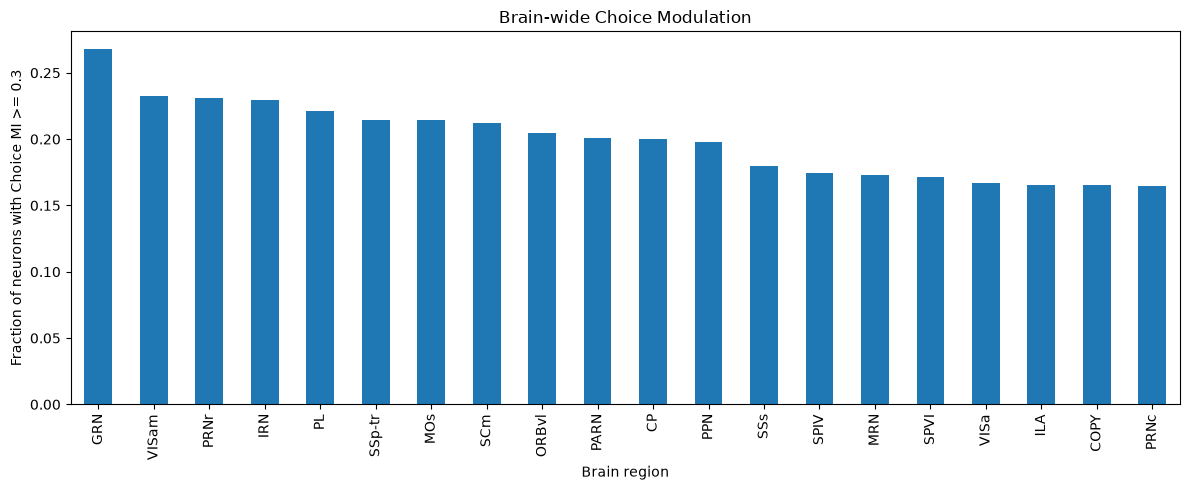

In [35]:
top_regions = brain_region_filtered.head(20)

ax = top_regions['high_mi_fraction'].plot(
    kind='bar',
    figsize=(12, 5)
)

ax.set_xlabel('Brain region')
ax.set_ylabel('Fraction of neurons with Choice MI >= 0.3')
ax.set_title('Brain-wide Choice Modulation')

plt.tight_layout()
plt.show()

# Extension B: Region-Wise Choice Decoding

Choice modulation measures whether neural activity differs between left and right choices, but the main question of this project is predictive:

**Can neural activity predict the animal's upcoming choice?**

We therefore train separate logistic-regression decoders for individual brain regions.

Importantly, decoding is performed separately within each probe insertion. We do not combine neurons from different sessions into a single feature matrix.

For each region-insertion pair, the logistic-regression accuracy is compared with a most-frequent dummy classifier evaluated on exactly the same test trials.

In [36]:
region_decoding_results = []

pids = meta.clusters['pid'].unique()

for pid_i in pids:

    psth_i, clust_i, trials_i = get_psth_for_insertion(
        pid_i,
        meta
    )

    # Reset cluster indices so they match the PSTH neuron axis
    clust_i = clust_i.reset_index(drop=True)

    # Sanity check: one metadata row per PSTH neuron
    assert psth_i.shape[1] == len(clust_i)

    y_i = trials_i.choice.values

    valid_trials = np.isin(y_i, [-1, 1])

    y_valid = y_i[valid_trials]

    # Skip sessions without both classes
    if len(np.unique(y_valid)) < 2:
        continue

    # Analyze each region recorded by this insertion
    for reg in clust_i['acronym'].dropna().unique():

        if reg in ['root', 'void']:
            continue

        # Positional indices of neurons belonging to this region
        cluster_indices = np.flatnonzero(
            clust_i['acronym'].to_numpy() == reg
        )

        if len(cluster_indices) < 5:
            continue

        # Require at least a few neurons
        if len(cluster_indices) < 5:
            continue

        X_reg = (
            psth_i[
                :,
                cluster_indices,
                :
            ][:, :, time_mask]
            .mean(axis=2)
        )

        X_reg = X_reg[valid_trials]

        X_train_reg, X_test_reg, y_train_reg, y_test_reg = (
            train_test_split(
                X_reg,
                y_valid,
                test_size=0.5,
                random_state=0,
                stratify=y_valid
            )
        )

        # Logistic regression
        clf_reg = LogisticRegression(
            random_state=0,
            max_iter=1000
        )

        # Scale neural features using training data only
        scaler_reg = StandardScaler()

        X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
        X_test_reg_scaled = scaler_reg.transform(X_test_reg)

        # Logistic regression
        clf_reg = LogisticRegression(
            random_state=0,
            max_iter=5000
        )

        clf_reg.fit(
            X_train_reg_scaled,
            y_train_reg
        )

        pred_reg = clf_reg.predict(
            X_test_reg_scaled
        )

        logistic_acc = accuracy_score(
            y_test_reg,
            pred_reg
        )

        # Dummy baseline
        dummy_reg = DummyClassifier(
            strategy='most_frequent'
        )

        dummy_reg.fit(
            X_train_reg,
            y_train_reg
        )

        dummy_pred = dummy_reg.predict(
            X_test_reg
        )

        dummy_acc = accuracy_score(
            y_test_reg,
            dummy_pred
        )

        region_decoding_results.append({
            'pid': pid_i,
            'acronym': reg,
            'n_clusters': len(cluster_indices),
            'logistic_accuracy': logistic_acc,
            'dummy_accuracy': dummy_acc,
            'accuracy_gain': logistic_acc - dummy_acc
        })

In [37]:
region_decoding_results = pd.DataFrame(
    region_decoding_results
)

region_decoding_results.head()

,pid,acronym,n_clusters,logistic_accuracy,dummy_accuracy,accuracy_gain
0,56f2a378-78d2-4132-b3c8-8c1ba82be598,MG,12,0.593909,0.573604,0.020305
1,56f2a378-78d2-4132-b3c8-8c1ba82be598,LGd,46,0.563452,0.573604,-0.010152
2,47be9ae4-290f-46ab-b047-952bc3a1a509,COAp,8,0.560976,0.577236,-0.016260
3,47be9ae4-290f-46ab-b047-952bc3a1a509,BMA,46,0.560976,0.577236,-0.016260
4,47be9ae4-290f-46ab-b047-952bc3a1a509,IA,10,0.609756,0.577236,0.032520


## Aggregate Decoding Performance Across Insertions

A brain region may be recorded in multiple independent probe insertions.

Rather than combining these recordings into one artificial neural population, we summarize the decoding performance obtained independently from each insertion.

For each region, we report the median logistic-regression accuracy, the median dummy accuracy, and the median improvement over the dummy baseline.

In [38]:
region_decoding_summary = (
    region_decoding_results
    .groupby('acronym')
    .agg(
        n_insertions=('pid', 'nunique'),

        median_accuracy=(
            'logistic_accuracy',
            'median'
        ),

        median_dummy_accuracy=(
            'dummy_accuracy',
            'median'
        ),

        median_accuracy_gain=(
            'accuracy_gain',
            'median'
        ),

        median_n_clusters=(
            'n_clusters',
            'median'
        )
    )
)

In [39]:
region_decoding_filtered = (
    region_decoding_summary[
        region_decoding_summary['n_insertions'] >= 3
    ]
    .sort_values(
        'median_accuracy_gain',
        ascending=False
    )
)

region_decoding_filtered.head(20)

,n_insertions,median_accuracy,median_dummy_accuracy,median_accuracy_gain,median_n_clusters
acronym,,,,,
GRN,14,0.813365,0.565069,0.242653,31.5
SNr,10,0.734663,0.544302,0.205096,10.5
PRNr,20,0.752533,0.552754,0.182918,39.5
RPF,4,0.766379,0.570736,0.171264,11.0
MA,3,0.681159,0.536232,0.144928,11.0
IRN,27,0.688889,0.560000,0.143541,28.0
SSp-ul,8,0.703640,0.545560,0.142486,15.5
MARN,3,0.746324,0.606618,0.139706,23.0
MDRN,7,0.773869,0.556291,0.139535,27.0


# Extension C: Combine Choice Modulation and Decoding Results

The two analyses provide complementary information:

- **Choice MI** measures how strongly neural activity differs between left and right choices.
- **Decoding accuracy** measures how well neural population activity predicts choice on held-out trials.

We therefore combine the region-level results to identify brain regions that show both strong choice-related modulation and useful predictive information.

In [40]:
combined_region_results = (
    brain_region_filtered
    .join(
        region_decoding_filtered,
        how='inner'
    )
)

combined_region_results = (
    combined_region_results
    .sort_values(
        'median_accuracy_gain',
        ascending=False
    )
)

combined_region_results[
    [
        'n_clusters',
        'median_choice_mi',
        'high_mi_fraction',
        'n_insertions',
        'median_accuracy',
        'median_dummy_accuracy',
        'median_accuracy_gain'
    ]
].head(20)

,n_clusters,median_choice_mi,high_mi_fraction,n_insertions,median_accuracy,median_dummy_accuracy,median_accuracy_gain
acronym,,,,,,,
GRN,560,0.152504,0.267857,14,0.813365,0.565069,0.242653
PRNr,770,0.138244,0.231169,20,0.752533,0.552754,0.182918
IRN,744,0.149193,0.229839,27,0.688889,0.560000,0.143541
MRN,2678,0.106998,0.172890,110,0.727017,0.555208,0.134718
SIM,893,0.099457,0.128779,19,0.726190,0.575269,0.132653
MV,672,0.095244,0.150298,20,0.704440,0.565069,0.126330
APN,1543,0.101696,0.160078,57,0.704280,0.538168,0.115646
GPe,322,0.069885,0.096273,11,0.707937,0.577236,0.113821
SCm,1666,0.128583,0.211885,62,0.714170,0.561485,0.113521
